In [1]:

# ==========================================
# DAY 6 - CELL 13: IMPORT CLUSTERING LIBRARIES
# ==========================================

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

print("Day 6 clustering libraries imported successfully!")


Day 6 clustering libraries imported successfully!


In [2]:

# ==========================================
# DAY 6 - CELL 14: LOAD AND COMBINE DATA
# ==========================================

train_path = "../data/processed/train_split.csv"
val_path = "../data/processed/val_split.csv"
test_path = "../data/processed/test_split.csv"

train_cluster_df = pd.read_csv(train_path)
val_cluster_df = pd.read_csv(val_path)
test_cluster_df = pd.read_csv(test_path)

cluster_data = pd.concat(
    [train_cluster_df, val_cluster_df, test_cluster_df],
    ignore_index=True
)

required_columns = ["Product ID", "Units Sold"]

missing_columns = [
    col for col in required_columns
    if col not in cluster_data.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing: {missing_columns}. "
        f"Available columns: {cluster_data.columns.tolist()}"
    )

cluster_data["Units Sold"] = pd.to_numeric(
    cluster_data["Units Sold"],
    errors="coerce"
)

cluster_data = cluster_data.dropna(
    subset=["Product ID", "Units Sold"]
)

print("Combined records:", len(cluster_data))
print("Unique products:", cluster_data["Product ID"].nunique())

display(cluster_data.head())


Combined records: 62600
Unique products: 20


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,...,DayOfWeek,Quarter,Is_Weekend,Units_Sold_Lag_1,Units_Sold_Lag_7,Rolling_Mean_7,Rolling_Std_7,Units_Sold_Lag_14,Units_Sold_Lag_28,Rolling_Mean_28
0,2022-02-05,S001,P0001,Groceries,South,458.0,350.0,182.0,362.43,51.44,...,5,1,1,25.0,47.0,156.142857,124.957898,191.0,2.0,136.642857
1,2022-02-06,S001,P0001,Electronics,North,167.0,69.0,92.0,81.06,68.85,...,6,1,1,350.0,130.0,147.428571,129.141856,79.0,350.0,126.607143
2,2022-02-07,S001,P0001,Electronics,South,244.0,62.0,105.0,73.41,11.34,...,0,1,0,69.0,200.0,127.714286,130.306964,9.0,36.0,127.535714
3,2022-02-08,S001,P0001,Toys,West,140.0,12.0,48.0,15.60,67.64,...,1,1,0,62.0,279.0,89.571429,117.045372,189.0,16.0,127.392857
4,2022-02-09,S001,P0001,Groceries,South,209.0,16.0,143.0,22.37,90.55,...,2,1,0,12.0,38.0,86.428571,118.940962,49.0,104.0,124.250000


In [3]:

# ==========================================
# DAY 6 - CELL 15: PRODUCT-LEVEL METRICS
# ==========================================

product_agg = {
    "Units Sold": ["sum", "mean", "median", "std", "count"]
}

# Include additional metrics only if available
optional_metrics = [
    "Price",
    "Discount",
    "Inventory Level",
    "Units Ordered"
]

for col in optional_metrics:
    if col in cluster_data.columns:
        cluster_data[col] = pd.to_numeric(
            cluster_data[col],
            errors="coerce"
        )
        product_agg[col] = ["mean"]

product_metrics = cluster_data.groupby("Product ID").agg(
    product_agg
)

# Flatten multi-level column names
product_metrics.columns = [
    "_".join(str(part) for part in col if part)
    for col in product_metrics.columns
]

product_metrics = product_metrics.reset_index()

product_metrics = product_metrics.rename(columns={
    "Units Sold_sum": "Total_Sales",
    "Units Sold_mean": "Average_Sales",
    "Units Sold_median": "Median_Sales",
    "Units Sold_std": "Sales_Std",
    "Units Sold_count": "Sales_Records"
})

# A product with only one record has undefined standard deviation
product_metrics["Sales_Std"] = (
    product_metrics["Sales_Std"].fillna(0)
)

print("Product-level metrics created!")
print("Product count:", len(product_metrics))
print("\nMetrics:")
print(product_metrics.columns.tolist())

display(product_metrics.head())


Product-level metrics created!
Product count: 20

Metrics:
['Product ID', 'Total_Sales', 'Average_Sales', 'Median_Sales', 'Sales_Std', 'Sales_Records', 'Price_mean', 'Discount_mean', 'Inventory Level_mean', 'Units Ordered_mean']


,Product ID,Total_Sales,Average_Sales,Median_Sales,Sales_Std,Sales_Records,Price_mean,Discount_mean,Inventory Level_mean,Units Ordered_mean
0,P0001,427454.0,136.566773,107.0,109.615072,3130,54.506495,10.196486,274.093291,111.498403
1,P0002,418337.0,133.653994,106.0,106.326118,3130,55.101495,9.835463,272.277636,110.273163
2,P0003,422451.0,134.968371,106.0,107.760535,3130,54.714728,9.977636,274.087220,110.042173
3,P0004,423565.0,135.324281,107.0,108.995527,3130,55.604438,10.020767,271.513099,107.279872
4,P0005,431439.0,137.839936,110.0,107.494340,3130,55.051102,9.760383,271.911821,108.859105


In [4]:

# ==========================================
# DAY 6 - CELL 16: FEATURE SELECTION & SCALING
# ==========================================

cluster_features = [
    col for col in product_metrics.columns
    if col != "Product ID"
    and pd.api.types.is_numeric_dtype(product_metrics[col])
]

# Remove columns with no useful variation or entirely missing values
cluster_features = [
    col for col in cluster_features
    if product_metrics[col].notna().any()
    and product_metrics[col].nunique(dropna=True) > 1
]

if len(product_metrics) < 3:
    raise ValueError(
        "At least 3 unique products are needed for this clustering workflow."
    )

if not cluster_features:
    raise ValueError("No suitable numerical clustering features found.")

X_cluster_df = product_metrics[cluster_features].copy()

# Replace infinite values and fill missing values with column medians
X_cluster_df = X_cluster_df.replace(
    [np.inf, -np.inf],
    np.nan
)

X_cluster_df = X_cluster_df.fillna(
    X_cluster_df.median()
)

# Standardize all numeric features
cluster_scaler = StandardScaler()

X_cluster_scaled = cluster_scaler.fit_transform(
    X_cluster_df
)

print("Features used for clustering:")
print(cluster_features)

print("\nScaled matrix shape:", X_cluster_scaled.shape)


Features used for clustering:
['Total_Sales', 'Average_Sales', 'Median_Sales', 'Sales_Std', 'Price_mean', 'Discount_mean', 'Inventory Level_mean', 'Units Ordered_mean']

Scaled matrix shape: (20, 8)


In [5]:

# ==========================================
# DAY 6 - CELL 17: COMPARE CLUSTER COUNTS
# ==========================================

max_k = min(5, len(product_metrics) - 1)

cluster_scores = []

for k in range(2, max_k + 1):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    # Silhouette requires at least 2 and fewer than n_samples clusters
    score = silhouette_score(
        X_cluster_scaled,
        labels
    )

    cluster_scores.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette_Score": score
    })

cluster_scores_df = pd.DataFrame(cluster_scores)

display(cluster_scores_df.round(4))

if cluster_scores_df.empty:
    raise ValueError(
        "Unable to compare cluster counts. Check the number of products."
    )

best_k = int(
    cluster_scores_df.loc[
        cluster_scores_df["Silhouette_Score"].idxmax(),
        "K"
    ]
)

print("\nSelected cluster count:", best_k)


,K,Inertia,Silhouette_Score
0,2,107.1736,0.3135
1,3,79.9902,0.2620
2,4,63.7755,0.2236
3,5,56.6457,0.1839



Selected cluster count: 2


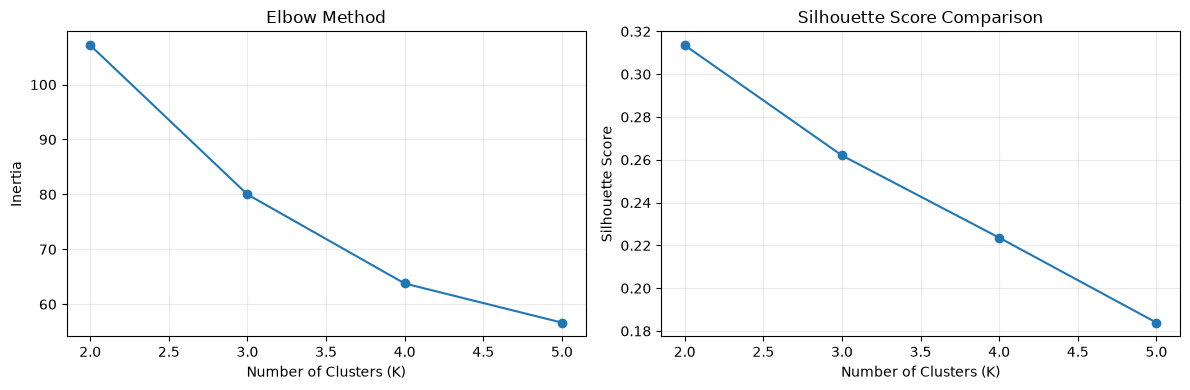

Selected K: 2


In [9]:

# ==========================================
# DAY 6 - CELL 21: CLUSTER COUNT COMPARISON
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    cluster_scores_df["K"],
    cluster_scores_df["Inertia"],
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.25)

axes[1].plot(
    cluster_scores_df["K"],
    cluster_scores_df["Silhouette_Score"],
    marker="o"
)
axes[1].set_title("Silhouette Score Comparison")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

print("Selected K:", best_k)


In [10]:

# ==========================================
# DAY 6 - CELL 22: SAVE CLUSTERING OUTPUTS
# ==========================================

os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# Save each product's cluster assignment
product_metrics.to_csv(
    "../data/processed/day6_product_clusters.csv",
    index=False
)

# Save cluster-level summary
cluster_profiles.to_csv(
    "../data/processed/day6_cluster_profiles.csv"
)

# Save K comparison results
cluster_scores_df.to_csv(
    "../data/processed/day6_cluster_scores.csv",
    index=False
)

# Save the fitted model, scaler, and feature information together
joblib.dump(
    {
        "model": kmeans_model,
        "scaler": cluster_scaler,
        "features": cluster_features,
        "best_k": best_k,
        "cluster_names": cluster_names
    },
    "../models/day6_kmeans_model.joblib"
)

print("Day 6 outputs saved successfully!")

print("\nSaved files:")
print("../data/processed/day6_product_clusters.csv")
print("../data/processed/day6_cluster_profiles.csv")
print("../data/processed/day6_cluster_scores.csv")
print("../models/day6_kmeans_model.joblib")


Day 6 outputs saved successfully!

Saved files:
../data/processed/day6_product_clusters.csv
../data/processed/day6_cluster_profiles.csv
../data/processed/day6_cluster_scores.csv
../models/day6_kmeans_model.joblib


In [11]:

# ==========================================
# DAY 6 - CELL 23: FINAL SUMMARY
# ==========================================

print("=" * 50)
print("DAY 6 - PRODUCT SEGMENTATION SUMMARY")
print("=" * 50)

print("Total products:", len(product_metrics))
print("Features used:", len(cluster_features))
print("Selected number of clusters:", best_k)

print("\nCluster distribution:")
print(
    product_metrics["Cluster_Profile"]
    .value_counts()
)

print("\nCluster profiles:")
display(cluster_profiles)

print("\nDay 6 product segmentation completed!")


DAY 6 - PRODUCT SEGMENTATION SUMMARY
Total products: 20
Features used: 8
Selected number of clusters: 2

Cluster distribution:
Cluster_Profile
Lower Average Sales     16
Higher Average Sales     4
Name: count, dtype: int64

Cluster profiles:


,Total_Sales,Average_Sales,Median_Sales,Sales_Std,Sales_Records,Price_mean,Discount_mean,Inventory Level_mean,Units Ordered_mean,Cluster_Profile
Cluster,,,,,,,,,,
0,425736.38,136.02,107.03,108.8,3130.0,55.08,10.02,273.98,109.74,Lower Average Sales
1,437406.00,139.75,112.12,109.8,3130.0,55.30,9.96,277.40,111.03,Higher Average Sales



Day 6 product segmentation completed!
